# <span style="color: #a855f7">Regression model comparison</span>

<span style="color: #a855f7">порівняння Linear, Polynomial, Ridge і Lasso на цінах авто, 10-Fold CV, регуляризація, вибір моделі, оцінка прогнозів</span>

In [1]:
import warnings
from html import escape
from urllib.request import urlopen

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import HTML, display
from sklearn.base import clone
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

DATA_URL = "https://raw.githubusercontent.com/arib168/data/main/CarPrice_Assignment.csv"
TEST_SIZE = 0.2
RANDOM_STATE = 42
CV_FOLDS = 10
COLORS = ["#a855f7", "#f472b6", "#60a5fa", "#facc15"]


def colorize(value, *, index=True):
    if isinstance(value, (pd.DataFrame, pd.Series)):
        table = value.to_frame() if isinstance(value, pd.Series) else value
        html = table.to_html(border=0, index=index).replace(
            '<table ', '<table style="color: #a855f7; margin-left: 0; margin-right: auto; border-collapse: collapse" '
        )
        for tag in ("th", "td"):
            html = html.replace(
                f"<{tag}>",
                f'<{tag} style="padding: 6px 12px; border-bottom: 1px solid #746a80">',
            )
        display(HTML(html))
    else:
        display(HTML(f'<pre style="color: #a855f7; background: transparent">{escape(str(value))}</pre>'))


def make_polynomial_pipeline(regressor):
    return Pipeline([
        ("poly", PolynomialFeatures(degree=3, include_bias=False)),
        ("scaler", StandardScaler()),
        ("model", regressor),
    ])


plt.style.use("dark_background")
plt.rcParams.update({
    "figure.figsize": (10, 5),
    "figure.dpi": 110,
    "figure.facecolor": "#111116",
    "axes.facecolor": "#111116",
    "axes.edgecolor": "#746a80",
    "axes.labelcolor": "#e9d5ff",
    "axes.titlecolor": "#e9d5ff",
    "axes.titlesize": 13,
    "text.color": "#e9d5ff",
    "xtick.color": "#d8c8ed",
    "ytick.color": "#d8c8ed",
    "grid.color": "#746a80",
    "grid.alpha": 0.25,
    "lines.linewidth": 2,
    "font.size": 10,
})

## <span style="color: #a855f7">Car data and train/test split</span>

<span style="color: #a855f7">той самий CSV із ТЗ, 205 авто, 5 заданих ознак, price у USD, split 80/20 з random_state = 42, для читання CSV потрібен інтернет, пропуски, нескінченні значення перевіряються до навчання</span>

In [2]:
with urlopen(DATA_URL, timeout=30) as response:
    df = pd.read_csv(response)
features = ["enginesize", "horsepower", "curbweight", "highwaympg", "carlength"]
required_columns = features + ["price"]
missing_columns = sorted(set(required_columns) - set(df.columns))
if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")
if len(df) != 205:
    raise ValueError(f"Expected 205 cars, received {len(df)}")
selected_data = df[required_columns].apply(pd.to_numeric, errors="raise")
if not np.isfinite(selected_data.to_numpy(dtype=float)).all():
    raise ValueError("Selected data must contain only finite numeric values")
if selected_data["price"].le(0).any():
    raise ValueError("Car prices must be positive")
X = selected_data[features].copy()
y = selected_data["price"].copy()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE,
)
if not X_train.index.intersection(X_test.index).empty:
    raise ValueError("Train and test rows must not overlap")
colorize(f"Dataset shape: {df.shape} | train size: {len(X_train)} | test size: {len(X_test)}")
colorize("Selected features and target: first 5 rows")
colorize(selected_data.head())

,enginesize,horsepower,curbweight,highwaympg,carlength,price
0,130,111,2548,27,168.8,13495.0
1,130,111,2548,27,168.8,16500.0
2,152,154,2823,26,171.2,16500.0
3,109,102,2337,30,176.6,13950.0
4,136,115,2824,22,176.6,17450.0


## <span style="color: #a855f7">Four model pipelines</span>

<span style="color: #a855f7">Linear: StandardScaler і LinearRegression, три інші моделі спочатку створюють 55 поліноміальних ознак degree=3 без bias, потім StandardScaler і відповідний регресор, alpha та max_iter збережені точно за ТЗ</span>

In [3]:
pipeline_lr = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LinearRegression()),
])
pipeline_poly = make_polynomial_pipeline(LinearRegression())
pipeline_ridge = make_polynomial_pipeline(Ridge(alpha=10))
pipeline_lasso = make_polynomial_pipeline(Lasso(alpha=0.1, max_iter=5000))
models = {
    "Linear Regression": pipeline_lr,
    "Polynomial (degree=3)": pipeline_poly,
    "Ridge (degree=3, alpha=10)": pipeline_ridge,
    "Lasso (degree=3, alpha=0.1)": pipeline_lasso,
}
model_settings = pd.DataFrame([
    {"model": "Linear Regression", "degree": 1, "features after expansion": 5, "penalty": "none", "alpha": "not applicable", "max_iter": "not applicable"},
    {"model": "Polynomial", "degree": 3, "features after expansion": 55, "penalty": "none", "alpha": "not applicable", "max_iter": "not applicable"},
    {"model": "Ridge", "degree": 3, "features after expansion": 55, "penalty": "L2", "alpha": "10", "max_iter": "solver default"},
    {"model": "Lasso", "degree": 3, "features after expansion": 55, "penalty": "L1", "alpha": "0.1", "max_iter": "5000"},
])
colorize(model_settings, index=False)

model,degree,features after expansion,penalty,alpha,max_iter
Linear Regression,1,5,none,not applicable,not applicable
Polynomial,3,55,none,not applicable,not applicable
Ridge,3,55,L2,10,solver default
Lasso,3,55,L1,0.1,5000


## <span style="color: #a855f7">10-Fold cross-validation</span>

<span style="color: #a855f7">cross_val_score працює на всьому X і y з cv=10, для регресії це KFold без перемішування, всі моделі отримують однакові fold, scaler навчається лише на навчальній частині кожного fold, std рахується з ddof=0 і не є довірчим інтервалом</span>

<span style="color: #a855f7">Lasso може не досягти збіжності за 5000 ітерацій на взаємопов'язаних поліноміальних ознаках, попередження збіжності збираються в діагностичну таблицю, параметри не змінюються і ці оцінки не подаються як гарантовано оптимізований розв'язок Lasso</span>

In [4]:
results = {}
cv_rows = []
convergence_diagnostics = []
for name, estimator in models.items():
    with warnings.catch_warnings(record=True) as warning_log:
        warnings.simplefilter("always", ConvergenceWarning)
        scores = np.asarray(cross_val_score(
            estimator, X, y, cv=CV_FOLDS, scoring="r2", error_score="raise",
        ), dtype=float)
    unexpected_warnings = [item for item in warning_log if not issubclass(item.category, ConvergenceWarning)]
    if unexpected_warnings:
        raise RuntimeError(f"Unexpected fit warning: {unexpected_warnings[0].message}")
    convergence_count = sum(issubclass(item.category, ConvergenceWarning) for item in warning_log)
    if scores.shape != (CV_FOLDS,) or not np.isfinite(scores).all():
        raise ValueError("Each model must produce ten finite cross-validation scores")
    results[name] = scores
    cv_rows.append({
        "model": name,
        "avg R²": scores.mean(),
        "std R²": scores.std(ddof=0),
        "avg ± std": f"{scores.mean():.4f} ± {scores.std(ddof=0):.4f}",
        "min R²": scores.min(),
        "max R²": scores.max(),
        "convergence warnings": convergence_count,
    })
    if convergence_count:
        convergence_diagnostics.append({
            "model": name,
            "affected folds": convergence_count,
            "total folds": CV_FOLDS,
            "status": "Iteration limit reached before convergence",
        })
cv_summary = pd.DataFrame(cv_rows).sort_values("avg R²", ascending=False).reset_index(drop=True)
colorize("Cross-validation ranking")
colorize(cv_summary[["model", "avg ± std", "min R²", "max R²", "convergence warnings"]].round(4), index=False)
colorize("Individual fold scores")
colorize(pd.DataFrame(results, index=np.arange(1, CV_FOLDS + 1)).rename_axis("fold").round(4))
if convergence_diagnostics:
    colorize("Convergence diagnostics")
    colorize(pd.DataFrame(convergence_diagnostics), index=False)

model,avg ± std,min R²,max R²,convergence warnings
"Ridge (degree=3, alpha=10)",0.3135 ± 0.5199,-0.7272,0.7889,0
Linear Regression,0.2801 ± 0.6398,-0.9676,0.7772,0
"Lasso (degree=3, alpha=0.1)",-0.5252 ± 1.3455,-3.9575,0.7878,10
Polynomial (degree=3),-17.1746 ± 40.2597,-136.2996,0.4097,0


,Linear Regression,Polynomial (degree=3),"Ridge (degree=3, alpha=10)","Lasso (degree=3, alpha=0.1)"
fold,,,,
1,0.6070,-0.1334,0.5721,0.3318
2,0.2026,-0.3029,0.5228,0.4631
3,0.7772,-1.8582,0.5694,-1.3955
4,0.7373,-22.8323,0.7889,0.7878
5,-0.9676,-0.4505,-0.6675,-0.6850
6,0.4818,-4.0699,0.5029,-0.9901
7,0.6570,-136.2996,0.2905,0.3118
8,0.5553,-6.2197,0.6006,-3.9575
9,-0.9559,0.0109,-0.7272,-0.6729


model,affected folds,total folds,status
"Lasso (degree=3, alpha=0.1)",10,10,Iteration limit reached before convergence


## <span style="color: #a855f7">Cross-validation boxplot</span>

<span style="color: #a855f7">розподіл 10 оцінок R² для кожної моделі, коробка показує середні 50% оцінок, лінія в коробці - median, точки поза вусами - статистичні викиди, всі від'ємні оцінки збережені, шкала symlog має лінійну область від -1 до 1</span>

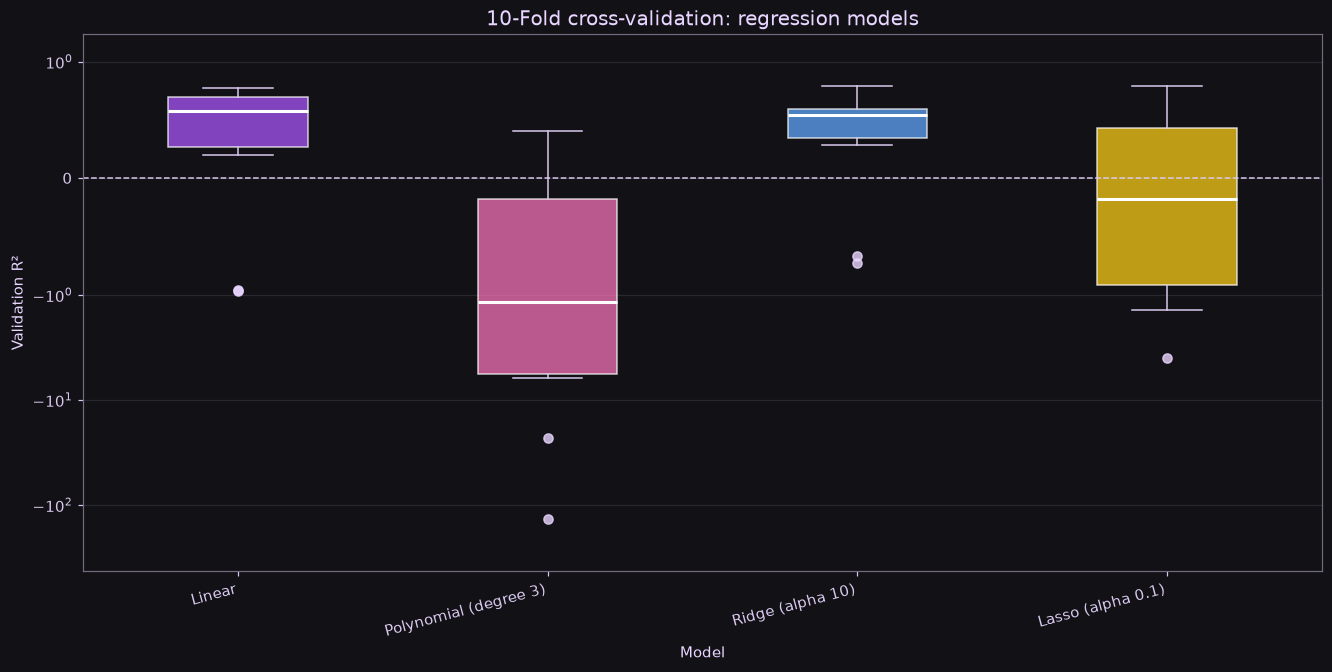

In [5]:
box_labels = ["Linear", "Polynomial (degree 3)", "Ridge (alpha 10)", "Lasso (alpha 0.1)"]
fig, ax = plt.subplots(figsize=(12, 6), layout="constrained")
boxes = ax.boxplot(
    list(results.values()), tick_labels=box_labels, patch_artist=True,
    medianprops={"color": "#ffffff", "linewidth": 2},
    whiskerprops={"color": "#d8c8ed"}, capprops={"color": "#d8c8ed"},
    flierprops={"marker": "o", "markerfacecolor": "#e9d5ff", "markeredgecolor": "#e9d5ff", "alpha": 0.8},
)
for box, color in zip(boxes["boxes"], COLORS, strict=True):
    box.set_facecolor(color)
    box.set_alpha(0.75)
ax.axhline(0, color="#d8c8ed", linestyle="--", linewidth=1)
ax.set_yscale("symlog", linthresh=1)
ax.margins(y=0.12)
ax.set(title="10-Fold cross-validation: regression models", xlabel="Model", ylabel="Validation R²")
ax.tick_params(axis="x", labelrotation=15)
plt.setp(ax.get_xticklabels(), ha="right")
ax.grid(axis="y")
ax.set_axisbelow(True)
plt.show()

## <span style="color: #a855f7">Best model and test metrics</span>

<span style="color: #a855f7">обирається модель з найвищим avg CV R², нова копія pipeline навчається лише на X_train, потім оцінюється на X_test, R² безрозмірний, MAE та RMSE - у USD</span>

<span style="color: #a855f7">за умовою CV використовує весь датасет, включно з рядками початкового test, тому вибір моделі вже враховує ці рядки, оцінка нижче виконує ТЗ, але не є повністю незалежною фінальною перевіркою, для нового проєкту CV для вибору моделі варто робити лише на train</span>

In [6]:
best_model_name = max(results, key=lambda name: float(results[name].mean()))
best_model = clone(models[best_model_name])
best_model.fit(X_train, y_train)
y_pred = np.asarray(best_model.predict(X_test), dtype=float)
if not np.isfinite(y_pred).all():
    raise ValueError("Test predictions must be finite")
test_r2 = r2_score(y_test, y_pred)
test_mae = mean_absolute_error(y_test, y_pred)
test_rmse = root_mean_squared_error(y_test, y_pred)
colorize(f"Selected model by highest avg CV R²: {best_model_name}")
colorize(pd.DataFrame({
    "test R²": [test_r2],
    "test MAE (USD)": [test_mae],
    "test RMSE (USD)": [test_rmse],
}).round({"test R²": 4, "test MAE (USD)": 2, "test RMSE (USD)": 2}), index=False)
colorize("First 5 test predictions")
colorize(pd.DataFrame({
    "actual (USD)": y_test.to_numpy(),
    "predicted (USD)": y_pred,
    "residual (USD)": y_test.to_numpy() - y_pred,
}, index=y_test.index).head().round(2))

test R²,test MAE (USD),test RMSE (USD)
0.8467,2326.66,3479.23


,actual (USD),predicted (USD),residual (USD)
15,30760.00,26746.58,4013.42
9,17859.17,18208.86,-349.70
100,9549.00,10825.33,-1276.33
132,11850.00,13772.85,-1922.85
68,28248.00,22924.14,5323.86


## <span style="color: #a855f7">Predicted vs actual</span>

<span style="color: #a855f7">по X - реальна ціна, по Y - передбачена, пунктир y=x показує ідеальний прогноз, обидві осі мають однакові межі й масштаб, точки вище лінії означають переоцінку, нижче - недооцінку</span>

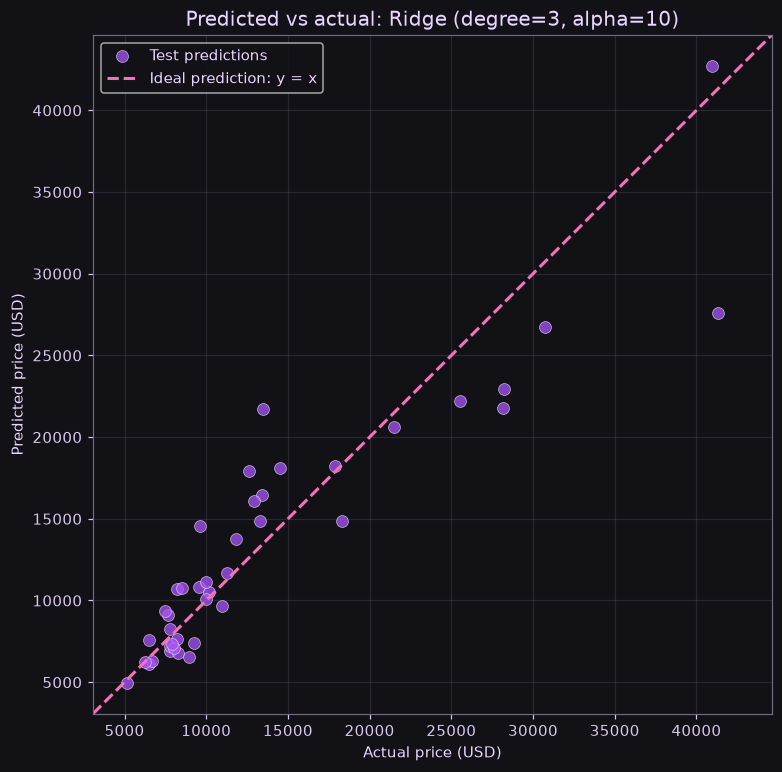

In [7]:
price_min = float(min(y_test.min(), y_pred.min()))
price_max = float(max(y_test.max(), y_pred.max()))
margin = (price_max - price_min) * 0.05
bounds = [price_min - margin, price_max + margin]
fig, ax = plt.subplots(figsize=(7, 7), layout="constrained")
ax.scatter(y_test.to_numpy(), y_pred, color=COLORS[0], edgecolors="#e9d5ff", linewidths=0.5, s=60, alpha=0.75, label="Test predictions")
ax.plot(bounds, bounds, color=COLORS[1], linestyle="--", label="Ideal prediction: y = x")
ax.set(title=f"Predicted vs actual: {best_model_name}", xlabel="Actual price (USD)", ylabel="Predicted price (USD)", xlim=bounds, ylim=bounds)
ax.set_aspect("equal", adjustable="box")
ax.legend()
ax.grid()
ax.set_axisbelow(True)
plt.show()

## <span style="color: #a855f7">Results and interpretation</span>

<span style="color: #a855f7">відповіді на контрольні питання за цими результатами</span>

<span style="color: #a855f7">1. Ridge з degree=3 і alpha=10 має найвищий avg CV R² серед заданих конфігурацій, нижчий розкид порівняно з нерегуляризованим поліномом підтримує вибір, фактичні оцінки відрізняються від приблизного прикладу в ТЗ, Lasso за 5000 ітерацій не досягає збіжності в усіх fold, тому його оцінки слід трактувати з цією умовою</span>

<span style="color: #a855f7">2. Ridge додає L2-штраф і стискає коефіцієнти, Lasso додає L1-штраф і може обнулити частину коефіцієнтів, відбір ознак Lasso залежить від alpha й даних</span>

<span style="color: #a855f7">3. CV перевіряє модель на кількох validation-частинах і показує розкид якості, це зменшує залежність висновку від одного split, але не гарантує точного прогнозу якості на будь-яких нових даних</span>

<span style="color: #a855f7">4. більший alpha посилює штраф, зменшує величину коефіцієнтів і може стримати перенавчання, надмірна регуляризація призводить до underfitting, однакові числові alpha у Ridge і Lasso не означають однакову силу штрафу</span>

<span style="color: #a855f7">5. поліноміальні ознаки доречні для нелінійних залежностей і взаємодій, ступінь та регуляризацію перевіряють через CV, на малих даних різко зростає ризик нестійких прогнозів, для цих 5 ознак degree=3 створює 55 колонок</span>